<a href="https://colab.research.google.com/github/Naveen-gale/DATA-SCENS-LEARNING/blob/main/resurach.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch_geometric
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from torch_geometric.datasets import Planetoid



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 866.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 7.7 MB/s eta 0:00:00


In [2]:
dataset = Planetoid(root="/tmp/Cora", name="Cora")
data = dataset[0]

print(data)

Processing...


Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])


Done!


In [3]:
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Number of node features: {data.num_node_features}')
print(f'Number of classes: {dataset.num_classes}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
print(f'validation node label rate: {int(data.val_mask.sum()) / data.num_nodes:.2f}')
print(f'test node label rate: {int(data.test_mask.sum()) / data.num_nodes:.2f}')

Number of nodes: 2708
Number of edges: 10556
Number of node features: 1433
Number of classes: 7
Number of training nodes: 140
Training node label rate: 0.05
validation node label rate: 0.18
test node label rate: 0.37


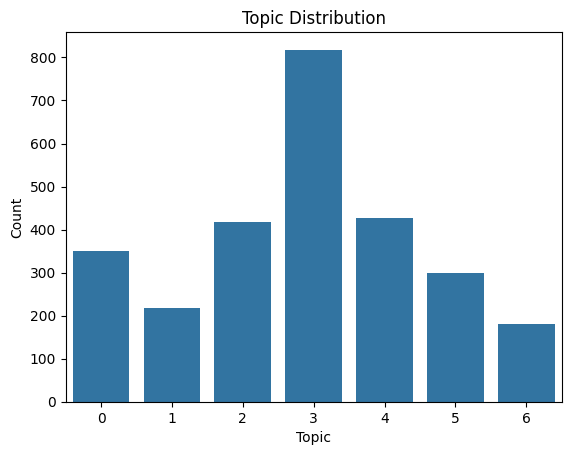

In [7]:
topic_count = pd.Series(data.y.numpy()).value_counts().sort_index()
sns.barplot(x=topic_count.index , y= topic_count.values)
plt.xlabel("Topic")
plt.ylabel("Count")
plt.title("Topic Distribution")
plt.show()


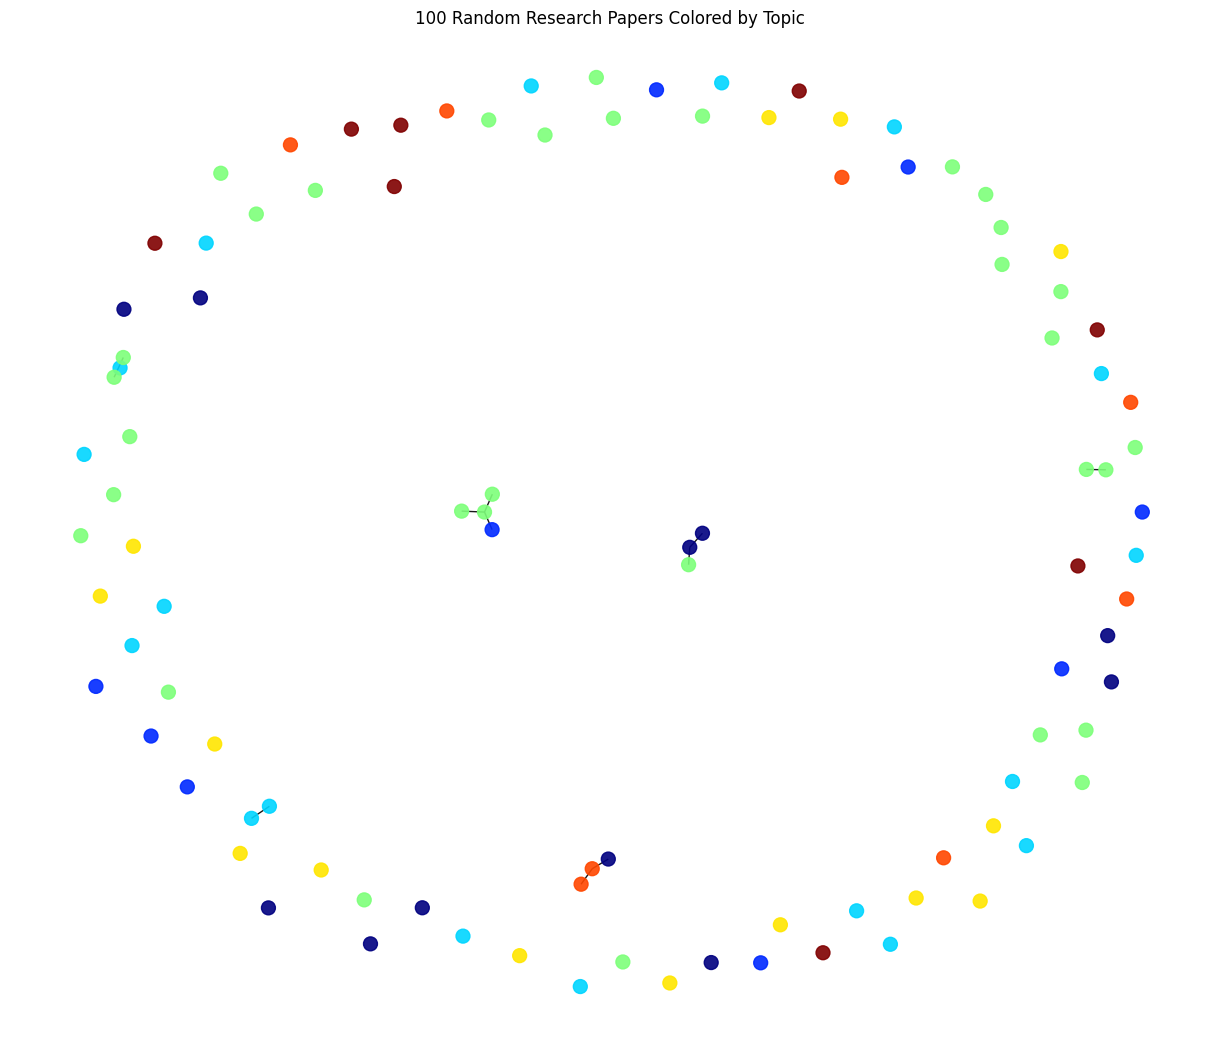

In [23]:
from torch_geometric.utils import to_networkx

import networkx as nx
import random
import matplotlib.pyplot as plt


SEED = 12345

# Convert the PyTorch Geometric data object to a NetworkX graph
G = to_networkx(data, to_undirected=True)

# Select 100 random nodes
random.seed(SEED)
sampled_nodes = random.sample(list(G.nodes()), 100)

# Create a graph using only those nodes
sample_graph = G.subgraph(sampled_nodes)

# Get the topic of each node
node_colors = [
    data.y[node].item()
    for node in sample_graph.nodes()
]

# Create positions for the nodes
pos = nx.spring_layout(sample_graph, seed=SEED)

# Draw the graph
plt.figure(figsize=(12, 10))

nx.draw(
    sample_graph,
    pos,
    node_color=node_colors,
    cmap=plt.cm.jet,
    node_size=100,
    alpha=0.9,
    with_labels=False
)

plt.title("100 Random Research Papers Colored by Topic")
plt.axis("off")
plt.show()


In [14]:
X_binary = data.x.numpy()
y = data.y.numpy()
print(x_binary.shape)
print(y.shape)

(2708, 1433)
(2708,)


In [18]:
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , f1_score, confusion_matrix

tfidf = TfidfTransformer()
X_tfidf = tfidf.fit_transform(X_binary).toarray()
X_baseline = X_tfidf #Features

train_idx = data.train_mask.numpy() #Training Research Papers
val_idx = data.val_mask.numpy()
test_idx = data.test_mask.numpy()

X_train , y_train = X_baseline[train_idx], y[train_idx]
X_test, y_test = X_baseline[test_idx],y[test_idx]

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
rf_r1= rf.score(X_test, y_test)
rf_acc = accuracy_score(y_test, y_pred)

print(f"Random Forest Accuracy: {rf_acc}")
print(f"Random Forest R1: {rf_r1}")



Random Forest Accuracy: 0.59
Random Forest R1: 0.59


<Axes: >

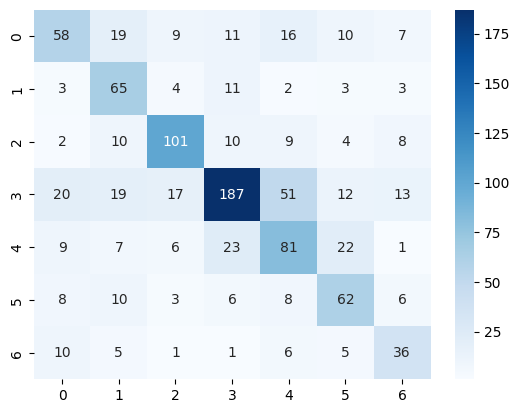

In [20]:
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=np.unique(y),
    yticklabels=np.unique(y)

)

In [28]:
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GCNConv
import torch , torch.nn.functional as F
from torch.nn import Dropout
class SimpleGCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(SimpleGCN, self).__init__()
        self.fc1 = GCNConv(input_dim, hidden_dim)
        self.fc2 = GCNConv(hidden_dim, output_dim)
        self.dropout =Dropout(0.5)


    def forward(self, x, edge_index):
        x = self.fc1(x, edge_index)
        x = F.relu(x)
        x = self.dropout(x)  # Use the module instance directly
        x = self.fc2(x, edge_index)
        return F.log_softmax(x, dim=1)



model = SimpleGCN(
    input_dim=dataset.num_features,
    hidden_dim=16,
    output_dim=dataset.num_classes
)



optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(model)

SimpleGCN(
  (fc1): GCNConv(1433, 16)
  (fc2): GCNConv(16, 7)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [31]:
def train_one_epoch():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()  # Corrected to call the method

@torch.no_grad()
def evaluate(mask):
    model.eval()
    logits = model(data.x, data.edge_index) # Pass full edge_index to the model
    predictions = logits.argmax(dim=1)
    accuracy = (predictions[mask] == data.y[mask]).float().mean().item() # Corrected accuracy calculation
    macro_f1 = f1_score(
        data.y[mask].numpy(),
        predictions[mask].numpy(),
        average="macro"
    )
    return accuracy, macro_f1, predictions

Epoch: 001 | Loss: 1.7834 | Train Acc: 0.9429 | Val Acc: 0.7020 | Best Val Acc: 0.7020
Epoch: 010 | Loss: 0.6094 | Train Acc: 0.9857 | Val Acc: 0.7780 | Best Val Acc: 0.7780
Epoch: 020 | Loss: 0.1718 | Train Acc: 1.0000 | Val Acc: 0.7760 | Best Val Acc: 0.7820
Epoch: 030 | Loss: 0.0874 | Train Acc: 1.0000 | Val Acc: 0.7740 | Best Val Acc: 0.7820
Early stopping at epoch 35

GCN test accuracy: 0.798
GCN test macro-F1: 0.793


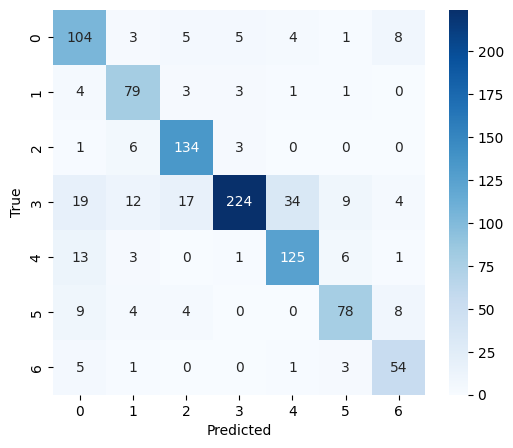

In [32]:
losses, train_accuracies, val_accuracies = [], [], []
best_val_accuracy = 0.0
best_state = None

epoch_without_improvement = 0
patience = 20 #Stop if no improvement for this many epochs

for epoch in range(1, 201):
  loss = train_one_epoch()
  train_accuracy,_,_ = evaluate(data.train_mask)
  val_accuracy,_,_ = evaluate(data.val_mask)

  losses.append(loss)
  train_accuracies.append(train_accuracy)
  val_accuracies.append(val_accuracy)

  if val_accuracy > best_val_accuracy:
    best_val_accuracy = val_accuracy
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()} # Clone state dict safely
    epoch_without_improvement = 0
  else:
    epoch_without_improvement += 1

  if epoch_without_improvement >= patience:
    print(f"Early stopping at epoch {epoch}")
    break

  if epoch == 1 or epoch % 10 == 0:
    print(f"Epoch: {epoch:03d} | Loss: {loss:.4f} | Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f} | Best Val Acc: {best_val_accuracy:.4f}")

model.load_state_dict(best_state)
gcn_accuracy, gcn_f1, gcn_pred = evaluate(data.test_mask)

print(f"\nGCN test accuracy: {gcn_accuracy:.3f}")
print(f"GCN test macro-F1: {gcn_f1:.3f}")

plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(data.y[data.test_mask].numpy(), gcn_pred[data.test_mask].numpy()),
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [37]:
result = pd.DataFrame(
    {
        "Model": ["GCN", "Random Forest"],
        "R1": [rf_r1, np.nan],
        "Accuracy": [gcn_accuracy, rf_acc],
        "Macro-F1": [gcn_f1, np.nan]
    }
)

In [38]:
result

,Model,R1,Accuracy,Macro-F1
0,GCN,0.59,0.798,0.79332
1,Random Forest,NaN,0.590,NaN


In [39]:
import random

# Ensure model is in evaluation mode
model.eval()

# Find the index of nodes belonging to the test set
test_indices = np.where(data.test_mask.numpy())[0]

# Select 5 random nodes from the test set
random.seed(42)
sampled_test_nodes = random.sample(list(test_indices), 5)

# Get model predictions (logits) for all nodes
with torch.no_grad():
    logits = model(data.x, data.edge_index)
    predictions = logits.argmax(dim=1).numpy()

print("=== Testing GCN Predictions on Real Test Data ===\n")
for node_id in sampled_test_nodes:
    true_label = data.y[node_id].item()
    predicted_label = predictions[node_id]
    is_correct = "✓ (Correct)" if true_label == predicted_label else "✗ (Incorrect)"

    print(f"Paper (Node ID): {node_id}")
    print(f"  True Category Class: {true_label}")
    print(f"  Predicted Class:     {predicted_label}  -> {is_correct}")
    print("-" * 40)

=== Testing GCN Predictions on Real Test Data ===

Paper (Node ID): 2362
  True Category Class: 4
  Predicted Class:     4  -> ✓ (Correct)
----------------------------------------
Paper (Node ID): 1822
  True Category Class: 3
  Predicted Class:     3  -> ✓ (Correct)
----------------------------------------
Paper (Node ID): 1733
  True Category Class: 2
  Predicted Class:     1  -> ✗ (Incorrect)
----------------------------------------
Paper (Node ID): 2467
  True Category Class: 6
  Predicted Class:     5  -> ✗ (Incorrect)
----------------------------------------
Paper (Node ID): 1989
  True Category Class: 2
  Predicted Class:     3  -> ✗ (Incorrect)
----------------------------------------
